In [1]:
!pip install seaborn


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from utils.preprocessing import *
from utils.config import *

Original data points: 19909
Aggregated data points: 665
Reduction ratio: 0.03


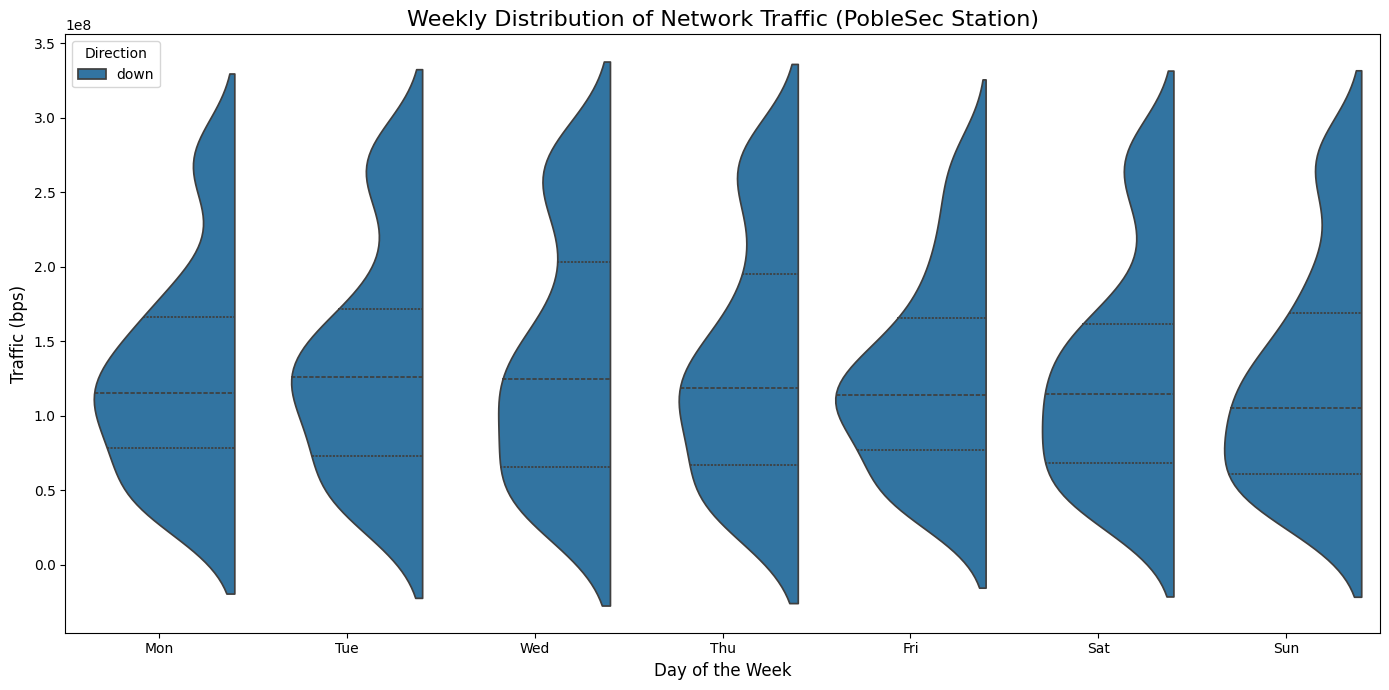

In [6]:
# Load raw data for PobleSec station
raw_df = load_all_data(POBLESEC_ST)

# Preprocess the data using the pipeline from preprocessing.py
preprocessed_df = data_pipeline(raw_df)

# Add weekday column (0=Monday, 6=Sunday)
preprocessed_df['weekday'] = preprocessed_df.index.weekday

# Aggregate by weekday: keep all values for violin plot
# Prepare data for seaborn: melt to long format for downlink/uplink
traffic_long = preprocessed_df.reset_index()[['weekday', 'down', 'up']]
traffic_long = traffic_long.melt(id_vars='weekday', value_vars=['down'],
                                 var_name='Direction', value_name='Traffic')

# Set y-axis label for bps
y_label = 'Traffic (bps)'

# Plot violin plot
plt.figure(figsize=(14, 7))
sns.violinplot(data=traffic_long, x='weekday', y='Traffic', hue='Direction', split=True, inner='quartile')
plt.title('Weekly Distribution of Network Traffic (PobleSec Station)', fontsize=16)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel(y_label, fontsize=12)
plt.xticks(ticks=range(7), labels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.tight_layout()
plt.show()